In [ ]:
!pip install langdetect

import pandas as pd
import numpy as np
import re
from langdetect import detect, DetectorFactory, LangDetectException

DetectorFactory.seed = 42
pd.set_option("display.max_columns", None)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 12.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993223 sha256=f3a64823e96317fbd09a12e43b2ff871e7906f78a5e1881fedf47f3bde3acdc2
  Stored in directory: /root/.cache/pip/wheels/c1/67/88/e844b5b022812e15a52e4eaa38a1e709e99f06f6639d7e3ba7
Successfully built langdetect


In [ ]:
def basic_eda(df, name):
    print(f"\n{'-'*50}")
    print(f"{name} dataframe")
    print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
    print(f"Duplicated rows: {df.duplicated(keep=False).sum()}")
    print(pd.concat([
        pd.DataFrame(df.dtypes, columns=["data_type"]),
        pd.DataFrame(df.isnull().sum(), columns=["num_nulls"])
    ], axis=1))


def remove_hyperlink(text):
    text = str(text)
    text = re.sub(r"http\S+|www\.\S+", "", text)
    return text


def remove_html(text):
    text = str(text)
    text = re.sub(r"<.*?>", " ", text)
    return text


def clean_whitespace(text):
    text = str(text)
    text = re.sub(r"[\r\n\t]+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def detect_lang_safe(text):
    text = str(text).strip()
    if len(text) < 15:
        return "unknown"
    try:
        return detect(text)
    except LangDetectException:
        return "unknown"
    except Exception:
        return "unknown"


def money_to_numeric(series):
    return pd.to_numeric(
        series.astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False),
        errors="coerce"
    )

In [ ]:
reviews = pd.read_csv("reviews.csv")
listings = pd.read_csv("listings.csv.gz")

basic_eda(reviews, "reviews_raw")
basic_eda(listings, "listings_raw")


--------------------------------------------------
reviews_raw dataframe
Rows: 544606 | Columns: 6
Duplicated rows: 0
              data_type  num_nulls
listing_id        int64          0
id                int64          0
date             object          0
reviewer_id       int64          0
reviewer_name    object          1
comments         object         33

--------------------------------------------------
listings_raw dataframe
Rows: 30051 | Columns: 79
Duplicated rows: 0
                                             data_type  num_nulls
id                                               int64          0
listing_url                                     object          0
scrape_id                                        int64          0
last_scraped                                    object          0
source                                          object          0
...                                                ...        ...
calculated_host_listings_count                   int64

In [ ]:
reviews.columns = reviews.columns.str.strip().str.lower()

# tarih
reviews["date"] = pd.to_datetime(reviews["date"], errors="coerce")

# comments null/boş temizliği
reviews = reviews.dropna(subset=["comments"]).copy()
reviews["comments"] = reviews["comments"].astype(str).str.strip()
reviews = reviews[reviews["comments"] != ""].copy()

# hyperlink + html + whitespace temizliği
reviews["comments"] = reviews["comments"].apply(remove_hyperlink)
reviews["comments"] = reviews["comments"].apply(remove_html)
reviews["comments"] = reviews["comments"].apply(clean_whitespace)

# yeniden boş kalanları at
reviews = reviews[reviews["comments"] != ""].copy()

# otomatik postingleri çıkar
pattern_auto = r"This is an automated posting|The host canceled this reservation|The reservation was canceled"
reviews = reviews[~reviews["comments"].str.contains(pattern_auto, case=False, na=False)].copy()

# çok kısa yorumları at
reviews["comment_len"] = reviews["comments"].str.len()
reviews = reviews[reviews["comment_len"] >= 5].copy()

reviews = reviews.reset_index(drop=True)

basic_eda(reviews, "reviews_clean_before_2025")
print(reviews[["date"]].agg(["min", "max"]))


--------------------------------------------------
reviews_clean_before_2025 dataframe
Rows: 537491 | Columns: 7
Duplicated rows: 0
                    data_type  num_nulls
listing_id              int64          0
id                      int64          0
date           datetime64[ns]          0
reviewer_id             int64          0
reviewer_name          object          1
comments               object          0
comment_len             int64          0
          date
min 2011-05-17
max 2025-09-30


In [ ]:
reviews_2025 = reviews[reviews["date"].dt.year == 2025].copy()
reviews_2025 = reviews_2025.reset_index(drop=True)

basic_eda(reviews_2025, "reviews_2025")
print(reviews_2025[["date"]].agg(["min", "max"]))


--------------------------------------------------
reviews_2025 dataframe
Rows: 131227 | Columns: 7
Duplicated rows: 0
                    data_type  num_nulls
listing_id              int64          0
id                      int64          0
date           datetime64[ns]          0
reviewer_id             int64          0
reviewer_name          object          0
comments               object          0
comment_len             int64          0
          date
min 2025-01-01
max 2025-09-30


In [ ]:
reviews_2025["language"] = reviews_2025["comments"].apply(detect_lang_safe)

print(reviews_2025["language"].value_counts().head(15))

language
en         55377
tr         35179
fr          7637
de          7555
unknown     6349
ar          4156
es          3585
ru          2921
it          1456
zh-cn       1063
nl          1030
ko           909
ro           499
pt           413
ja           354
Name: count, dtype: int64


In [ ]:
reviews_2025_lang = reviews_2025[reviews_2025["language"].isin(["en", "tr"])].copy()
reviews_2025_lang = reviews_2025_lang.reset_index(drop=True)

print(reviews_2025_lang["language"].value_counts())
basic_eda(reviews_2025_lang, "reviews_2025_en_tr")

language
en    55377
tr    35179
Name: count, dtype: int64

--------------------------------------------------
reviews_2025_en_tr dataframe
Rows: 90556 | Columns: 8
Duplicated rows: 0
                    data_type  num_nulls
listing_id              int64          0
id                      int64          0
date           datetime64[ns]          0
reviewer_id             int64          0
reviewer_name          object          0
comments               object          0
comment_len             int64          0
language               object          0


In [ ]:
listings.columns = listings.columns.str.strip().str.lower()

# id
listings["id"] = pd.to_numeric(listings["id"], errors="coerce")
listings = listings.dropna(subset=["id"]).copy()
listings["id"] = listings["id"].astype(int)

# host_listings_count yerine calculated_host_listings_count kullan
if "host_listings_count" in listings.columns and "calculated_host_listings_count" in listings.columns:
    listings = listings.drop(columns=["host_listings_count"])

# fiyat kolonları
for col in ["price", "extra_people", "cleaning_fee", "security_deposit"]:
    if col in listings.columns:
        if col in ["cleaning_fee", "security_deposit"]:
            listings[col] = listings[col].fillna(0)
        listings[col] = money_to_numeric(listings[col])

# reviews_per_month
if "reviews_per_month" in listings.columns:
    listings["reviews_per_month"] = listings["reviews_per_month"].fillna(0)

# host response / acceptance
for col in ["host_response_rate", "host_acceptance_rate"]:
    if col in listings.columns:
        listings[col] = pd.to_numeric(
            listings[col].astype(str).str.replace("%", "", regex=False),
            errors="coerce"
        )

# host flags
for col in ["host_is_superhost", "host_identity_verified"]:
    if col in listings.columns:
        listings[col] = listings[col].fillna("f")

if "host_response_time" in listings.columns:
    listings["host_response_time"] = listings["host_response_time"].fillna("unknown")

# bathrooms
if "bathrooms" in listings.columns:
    listings["bathrooms"] = listings["bathrooms"].fillna(1)

# bedrooms / beds -> accommodates bazlı median
if "accommodates" in listings.columns:
    listings["accommodates"] = pd.to_numeric(listings["accommodates"], errors="coerce")

for target_col in ["bedrooms", "beds"]:
    if target_col in listings.columns and "accommodates" in listings.columns:
        med_map = listings.groupby("accommodates")[target_col].median()
        listings[target_col] = listings[target_col].fillna(listings["accommodates"].map(med_map))

# tarih kolonları
for col in ["host_since", "first_review", "last_review"]:
    if col in listings.columns:
        listings[col] = pd.to_datetime(listings[col], errors="coerce")

# istersen hafifçe bazı açıkça gereksiz kolonları çıkar
drop_cols_light = [
    "listing_url", "scrape_id", "last_scraped", "thumbnail_url", "medium_url",
    "picture_url", "xl_picture_url", "host_url", "host_name", "host_location",
    "host_about", "host_thumbnail_url", "host_picture_url"
]
drop_cols_light = [c for c in drop_cols_light if c in listings.columns]
listings_clean = listings.drop(columns=drop_cols_light).copy()

basic_eda(listings_clean, "listings_clean")


--------------------------------------------------
listings_clean dataframe
Rows: 30051 | Columns: 68
Duplicated rows: 0
                                             data_type  num_nulls
id                                               int64          0
source                                          object          0
name                                            object          0
description                                     object        797
neighborhood_overview                           object      21953
...                                                ...        ...
calculated_host_listings_count                   int64          0
calculated_host_listings_count_entire_homes      int64          0
calculated_host_listings_count_private_rooms     int64          0
calculated_host_listings_count_shared_rooms      int64          0
reviews_per_month                              float64          0

[68 rows x 2 columns]


In [ ]:
master_2025 = pd.merge(
    reviews_2025_lang,
    listings_clean,
    left_on="listing_id",
    right_on="id",
    how="inner"
)

master_2025 = master_2025.reset_index(drop=True)

print(master_2025.shape)
print(master_2025["language"].value_counts())
basic_eda(master_2025, "master_2025")

(90556, 76)
language
en    55377
tr    35179
Name: count, dtype: int64

--------------------------------------------------
master_2025 dataframe
Rows: 90556 | Columns: 76
Duplicated rows: 0
                                                   data_type  num_nulls
listing_id                                             int64          0
id_x                                                   int64          0
date                                          datetime64[ns]          0
reviewer_id                                            int64          0
reviewer_name                                         object          0
...                                                      ...        ...
calculated_host_listings_count                         int64          0
calculated_host_listings_count_entire_homes            int64          0
calculated_host_listings_count_private_rooms           int64          0
calculated_host_listings_count_shared_rooms            int64          0
reviews_per_month 

In [ ]:
reviews_2025_lang.to_csv("reviews_2025_en_tr.csv", index=False)
listings_clean.to_csv("listings_clean.csv", index=False)
master_2025.to_csv("master_2025_en_tr.csv", index=False)

print("Dosyalar kaydedildi.")

Dosyalar kaydedildi.


In [ ]:
import pandas as pd

df = pd.read_csv("master_2025_en_tr.csv")

df_en = df[df["language"] == "en"].copy()
df_tr = df[df["language"] == "tr"].copy()

n_analysis = 3000

en_analysis = df_en.sample(n=min(n_analysis, len(df_en)), random_state=42).copy()
tr_analysis = df_tr.sample(n=min(n_analysis, len(df_tr)), random_state=42).copy()

print(en_analysis.shape, tr_analysis.shape)

en_analysis.to_csv("airbnb_en_analysis_3000.csv", index=False)
tr_analysis.to_csv("airbnb_tr_analysis_3000.csv", index=False)

(3000, 76) (3000, 76)


In [ ]:
import pandas as pd
import re
import nltk

nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab")

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

df_en = pd.read_csv("airbnb_en_analysis_3000.csv")
df_tr = pd.read_csv("airbnb_tr_analysis_3000.csv")

stop_words_en = set(stopwords.words("english"))
stop_words_tr = set(stopwords.words("turkish"))

custom_en = {"apartment", "stay", "place", "room", "host"}
custom_tr = {"ev", "yer", "konaklama"}

stop_words_en = stop_words_en.union(custom_en)
stop_words_tr = stop_words_tr.union(custom_tr)

def basic_clean_text(text, lang="en"):
    if pd.isna(text):
        return ""
    text = str(text).lower().strip()
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    text = re.sub(r"[\r\n\t]+", " ", text)
    text = re.sub(r"\d+", " ", text)

    if lang == "en":
        text = re.sub(r"[^a-z\s]", " ", text)
    else:
        text = re.sub(r"[^a-zA-ZçğıöşüÇĞİÖŞÜ\s]", " ", text)
        text = text.lower()

    text = re.sub(r"\s+", " ", text).strip()
    return text

def preprocess_and_tokenize(text, lang="en"):
    cleaned = basic_clean_text(text, lang=lang)
    if cleaned == "":
        return "", []
    tokens = word_tokenize(cleaned)
    if lang == "en":
        tokens = [tok for tok in tokens if tok not in stop_words_en and len(tok) > 2]
    else:
        tokens = [tok for tok in tokens if tok not in stop_words_tr and len(tok) > 2]
    clean_text = " ".join(tokens)
    return clean_text, tokens

df_en[["clean_text", "tokens"]] = df_en["comments"].apply(lambda x: pd.Series(preprocess_and_tokenize(x, "en")))
df_tr[["clean_text", "tokens"]] = df_tr["comments"].apply(lambda x: pd.Series(preprocess_and_tokenize(x, "tr")))

df_en = df_en[df_en["clean_text"] != ""].copy()
df_tr = df_tr[df_tr["clean_text"] != ""].copy()

df_en.to_csv("airbnb_en_analysis_3000_preprocessed.csv", index=False)
df_tr.to_excel("airbnb_tr_analysis_3000_preprocessed.xlsx", index=False)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [ ]:
import pandas as pd
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download("vader_lexicon")

df_en = pd.read_csv("airbnb_en_analysis_3000_preprocessed.csv")

sia = SentimentIntensityAnalyzer()

def get_sentiment_score(text):
    return sia.polarity_scores(str(text))["compound"]
def label_sentiment(score):
    if score >= 0.05:
        return "positive"
    elif score <= 0.05:
        return "negative"

df_en["sentiment_score"] = df_en["comments"].apply(get_sentiment_score)
df_en["sentiment_label"] = df_en["sentiment_score"].apply(label_sentiment)

df_en.to_csv("airbnb_en_analysis_3000_sentiment.csv", index=False)
print(df_en["sentiment_label"].value_counts())
print(df_en["sentiment_score"].describe())

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


sentiment_label
positive    2885
negative     115
Name: count, dtype: int64
count    3000.000000
mean        0.804154
std         0.297267
min        -0.988200
25%         0.781000
50%         0.910000
75%         0.963600
max         0.997800
Name: sentiment_score, dtype: float64


In [ ]:
import os
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

# =========================================================
# 1) DOSYA ADI
# =========================================================
file_path = "airbnb_tr_analysis_3000_preprocessed_labeled.xlsx"

# Sabit split dosyaları
train_ids_file = "fixed_train_ids.xlsx"
val_ids_file   = "fixed_val_ids.xlsx"
test_ids_file  = "fixed_test_ids.xlsx"

# =========================================================
# 2) DOSYAYI OKU
# =========================================================
df = pd.read_excel(file_path)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

# =========================================================
# 3) METİN SÜTUNUNU BUL
# =========================================================
candidate_text_cols = ["clean_text", "comments_clean", "comments", "review_text", "text"]
text_col = None

for col in candidate_text_cols:
    if col in df.columns:
        text_col = col
        break

if text_col is None:
    raise ValueError("Metin sütunu bulunamadı.")

print("Kullanılan metin sütunu:", text_col)

# =========================================================
# 4) ETİKET SÜTUNUNU BUL
# =========================================================
candidate_label_cols = ["manuel_label", "manuel_label.1", "manual_label"]
label_col = None
best_count = -1

for col in candidate_label_cols:
    if col in df.columns:
        temp = df[col].astype(str).str.strip().str.lower()
        count_valid = temp.isin(["positive", "negative", "mixed"]).sum()
        if count_valid > best_count:
            best_count = count_valid
            label_col = col

if label_col is None:
    raise ValueError("Etiket sütunu bulunamadı.")

print("Kullanılan etiket sütunu:", label_col)

df[label_col] = df[label_col].astype(str).str.strip().str.lower()
df[label_col] = df[label_col].replace({
    "": np.nan,
    "nan": np.nan,
    "none": np.nan
})

# =========================================================
# 5) SADECE ETİKETLİ SATIRLAR
# =========================================================
valid_labels = ["positive", "negative", "mixed"]
labeled_df = df[df[label_col].isin(valid_labels)].copy()

print("\nEtiketli satır sayısı:", len(labeled_df))
print("\nOrijinal etiket dağılımı:")
print(labeled_df[label_col].value_counts())

# =========================================================
# 6) BINARY ETİKET
# positive -> positive
# negative + mixed -> non_positive
# =========================================================
label_map = {
    "positive": "positive",
    "negative": "non_positive",
    "mixed": "non_positive"
}
labeled_df["binary_label"] = labeled_df[label_col].map(label_map)

print("\nBinary etiket dağılımı:")
print(labeled_df["binary_label"].value_counts())

# =========================================================
# 7) ID SÜTUNU BUL
# =========================================================
candidate_id_cols = ["id_x", "id", "row_id"]
id_col = None

for col in candidate_id_cols:
    if col in labeled_df.columns:
        id_col = col
        break

if id_col is None:
    raise ValueError("ID sütunu bulunamadı. id_x / id / row_id bekleniyor.")

print("Kullanılan ID sütunu:", id_col)

# =========================================================
# 8) SABİT SPLIT OLUŞTUR / YÜKLE
# Eğer dosyalar varsa onları kullanır.
# Yoksa ilk kez oluşturur.
# =========================================================
if os.path.exists(train_ids_file) and os.path.exists(val_ids_file) and os.path.exists(test_ids_file):
    print("\nSabit split dosyaları bulundu, yükleniyor...")
    train_ids = pd.read_excel(train_ids_file)
    val_ids   = pd.read_excel(val_ids_file)
    test_ids  = pd.read_excel(test_ids_file)
else:
    print("\nSabit split dosyaları bulunamadı, yeni split oluşturuluyor...")

    ids = labeled_df[[id_col, "binary_label"]].drop_duplicates().copy()

    # Önce test (%15)
    train_val_ids, test_ids = train_test_split(
        ids,
        test_size=0.15,
        random_state=42,
        stratify=ids["binary_label"]
    )

    # Sonra validation (%15 toplam olsun diye kalan %85'in içinden böl)
    train_ids, val_ids = train_test_split(
        train_val_ids,
        test_size=0.1764705882,   # yaklaşık toplam %15 validation
        random_state=42,
        stratify=train_val_ids["binary_label"]
    )

    train_ids.to_excel(train_ids_file, index=False)
    val_ids.to_excel(val_ids_file, index=False)
    test_ids.to_excel(test_ids_file, index=False)

    print("Kaydedildi:")
    print("-", train_ids_file)
    print("-", val_ids_file)
    print("-", test_ids_file)

# =========================================================
# 9) SABİT SPLIT UYGULA
# =========================================================
train_df = labeled_df[labeled_df[id_col].isin(train_ids[id_col])].copy()
val_df   = labeled_df[labeled_df[id_col].isin(val_ids[id_col])].copy()
test_df  = labeled_df[labeled_df[id_col].isin(test_ids[id_col])].copy()

print("\nTrain:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTrain dağılımı:")
print(train_df["binary_label"].value_counts())

print("\nValidation dağılımı:")
print(val_df["binary_label"].value_counts())

print("\nTest dağılımı:")
print(test_df["binary_label"].value_counts())

# =========================================================
# 10) X / y
# =========================================================
X_train = train_df[text_col].astype(str)
y_train = train_df["binary_label"]

X_val = val_df[text_col].astype(str)
y_val = val_df["binary_label"]

X_test = test_df[text_col].astype(str)
y_test = test_df["binary_label"]

# =========================================================
# 11) MODELLER
# =========================================================
models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("clf", LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("clf", LinearSVC(
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("clf", MultinomialNB(alpha=1.0))
    ])
}

# =========================================================
# 12) HER MODELİ ÇALIŞTIR
# =========================================================
results = []

for model_name, model in models.items():
    print("\n" + "="*70)
    print(f"MODEL: {model_name}")
    print("="*70)

    model.fit(X_train, y_train)

    # VALIDATION
    val_pred = model.predict(X_val)

    val_acc = accuracy_score(y_val, val_pred)
    val_f1  = f1_score(y_val, val_pred, average="macro")

    print(f"\n===== {model_name} | VALIDATION RESULTS =====")
    print("Accuracy:", val_acc)
    print("Macro F1:", val_f1)
    print("\nClassification Report:")
    print(classification_report(y_val, val_pred))
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_val, val_pred))

    # TEST
    test_pred = model.predict(X_test)

    test_acc = accuracy_score(y_test, test_pred)
    test_f1  = f1_score(y_test, test_pred, average="macro")

    print(f"\n===== {model_name} | TEST RESULTS =====")
    print("Accuracy:", test_acc)
    print("Macro F1:", test_f1)
    print("\nClassification Report:")
    print(classification_report(y_test, test_pred))
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, test_pred))

    results.append({
        "Model": model_name,
        "Validation Accuracy": val_acc,
        "Validation Macro F1": val_f1,
        "Test Accuracy": test_acc,
        "Test Macro F1": test_f1
    })

# =========================================================
# 13) KARŞILAŞTIRMA TABLOSU
# =========================================================
comparison_df = pd.DataFrame(results).sort_values("Test Macro F1", ascending=False)

print("\n" + "="*70)
print("MODEL COMPARISON TABLE")
print("="*70)
print(comparison_df)

comparison_df.to_excel("model_comparison_table.xlsx", index=False)
print("\nKaydedildi: model_comparison_table.xlsx")

Shape: (3000, 80)
Columns: ['listing_id', 'id_x', 'date', 'reviewer_id', 'reviewer_name', 'comments', 'comment_len', 'language', 'id_y', 'source', 'name', 'description', 'neighborhood_overview', 'host_id', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'calendar_updated', 'has_availability', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'calendar_last_scraped', 'number_of_revi

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Final model = Logistic Regression
final_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("clf", LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ))

])

# Tüm etiketli veriyle eğit
X_all = labeled_df[text_col].astype(str)
y_all = labeled_df["binary_label"]

final_model.fit(X_all, y_all)

print("Final model tüm etiketli veriyle eğitildi.")

Final model tüm etiketli veriyle eğitildi.


In [ ]:
# Etiketsiz satırları al
unlabeled_df = df[~df[label_col].isin(valid_labels)].copy()

print("Etiketsiz satır sayısı:", len(unlabeled_df))

# Tahmin yap
if len(unlabeled_df) > 0:
    unlabeled_df["predicted_binary_label"] = final_model.predict(unlabeled_df[text_col].astype(str))

    print("\nTahmin edilen etiket dağılımı:")
    print(unlabeled_df["predicted_binary_label"].value_counts())

    tr_probabilities = final_model.predict_proba(unlabeled_df[text_col].astype(str))
    unlabeled_df["sentiment_continuous_score"] = tr_probabilities[:, 1]

    print("\nTahmin ve Sürekli Skor Üretimi Tamamlandı!")
    print(unlabeled_df[["comments", "predicted_binary_label", "sentiment_continuous_score"]].head())

    # Etiketli ve etiketsiz veriyi birleştir
    labeled_df["final_binary_label"] = labeled_df["binary_label"]
    unlabeled_df["final_binary_label"] = unlabeled_df["predicted_binary_label"]

    final_df = pd.concat([labeled_df, unlabeled_df], axis=0).sort_index()

    print("\nTüm veri için final dağılım:")
    print(final_df["final_binary_label"].value_counts())

    final_df.to_excel("tr_3000_with_final_binary_labels.xlsx", index=False)
    print("\nKaydedildi: tr_3000_with_final_binary_labels.xlsx")
else:
    print("Etiketsiz satır yok.")

Etiketsiz satır sayısı: 2436

Tahmin edilen etiket dağılımı:
predicted_binary_label
positive        2159
non_positive     277
Name: count, dtype: int64

Tahmin ve Sürekli Skor Üretimi Tamamlandı!
                                              comments predicted_binary_label  \
519  Her şey için teşekkür ederiz kesinlikle tavsiy...               positive   
520  Son derece kusursuz bir konaklama süreci geçir...               positive   
521  Evin konumu çok iyiydi, giriş sorunsuzdu. Resi...               positive   
522                       Misafirperver, iyi ev sahibi               positive   
523  Geniş, ferah ve aydınlık bir mekan. Konum çok ...               positive   

     sentiment_continuous_score  
519                    0.903159  
520                    0.544520  
521                    0.610157  
522                    0.736072  
523                    0.743018  

Tüm veri için final dağılım:
final_binary_label
positive        2601
non_positive     399
Name: count, dtype: in

TR shape: (3000, 84)
EN shape: (3000, 80)

TR final label dağılımı:
final_binary_label_std
positive        2601
non_positive     399
Name: count, dtype: int64

EN final label dağılımı:
final_binary_label_std
positive        2885
non_positive     115
Name: count, dtype: int64

Combined shape: (6000, 88)
Dosya kaydedildi: tr_en_binary_combined.xlsx

=== COUNT TABLE ===
final_binary_label_std  non_positive  positive
language_group                                
English                          115      2885
Turkish                          399      2601

=== PERCENTAGE TABLE ===
final_binary_label_std  non_positive  positive
language_group                                
English                         3.83     96.17
Turkish                        13.30     86.70


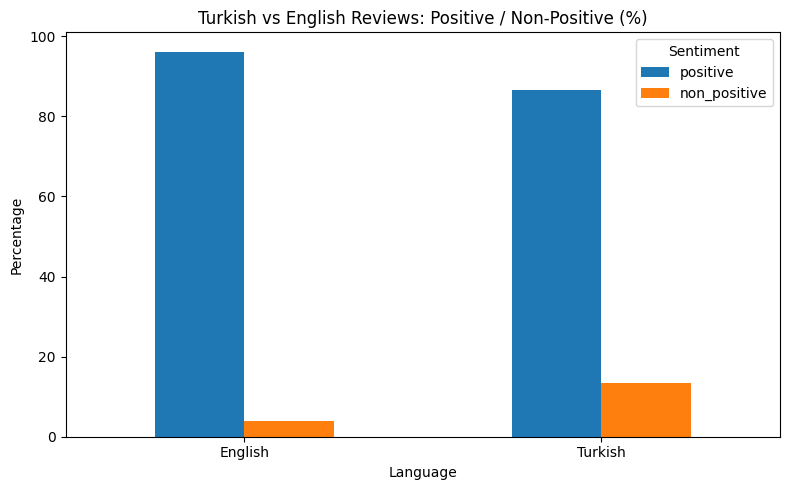

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1) DOSYALARI OKU
# =========================================================
tr_file = "tr_3000_with_final_binary_labels.xlsx"
en_file = "airbnb_en_analysis_3000_sentiment.csv"

tr_df = pd.read_excel(tr_file)
en_df = pd.read_csv(en_file)

print("TR shape:", tr_df.shape)
print("EN shape:", en_df.shape)

# =========================================================
# 2) BINARY LABEL HAZIRLAMA FONKSİYONU
# Eğer final_binary_label varsa onu kullanır
# Yoksa manuel_label / manuel_label.1 içinden üretir
# =========================================================
def prepare_binary_df(df, language_name):
    df = df.copy()

    # Önce binary hazır sütun var mı bak
    binary_candidates = ["final_binary_label", "predicted_binary_label", "binary_label", "sentiment_label"]
    label_col = None

    for col in binary_candidates:
        if col in df.columns:
            label_col = col
            break

    if label_col is not None:
        df["final_binary_label_std"] = df[label_col].astype(str).str.strip().str.lower()

        # Map English specific labels to binary labels
        if language_name == "English":
            df["final_binary_label_std"] = df["final_binary_label_std"].replace({
                "negative": "non_positive",
                "neutral": "non_positive"
            })

    # Eğer hazır binary yoksa 3 sınıflı etiketten üret (primarily for Turkish manual labels)
    else:
        manual_candidates = ["manuel_label", "manuel_label.1", "manual_label"]
        best_count = -1
        best_col = None

        for col in manual_candidates:
            if col in df.columns:
                temp = df[col].astype(str).str.strip().str.lower()
                count_valid = temp.isin(["positive", "negative", "mixed"]).sum()
                if count_valid > best_count:
                    best_count = count_valid
                    best_col = col

        if best_col is None:
            raise ValueError(f"{language_name} dosyasında uygun etiket sütunu bulunamadı.")

        df[best_col] = df[best_col].astype(str).str.strip().str.lower()

        label_map = {
            "positive": "positive",
            "negative": "non_positive",
            "mixed": "non_positive"
        }

        df["final_binary_label_std"] = df[best_col].map(label_map)

    # sadece geçerli etiketleri al
    df = df[df["final_binary_label_std"].isin(["positive", "non_positive"])].copy()
    df["language_group"] = language_name

    return df

# =========================================================
# 3) TÜRKÇE VE İNGİLİZCEYİ HAZIRLA
# =========================================================
tr_ready = prepare_binary_df(tr_df, "Turkish")
en_ready = prepare_binary_df(en_df, "English")

print("\nTR final label dağılımı:")
print(tr_ready["final_binary_label_std"].value_counts())

print("\nEN final label dağılımı:")
print(en_ready["final_binary_label_std"].value_counts())

# =========================================================
# 4) BİRLEŞTİR
# =========================================================
combined = pd.concat([tr_ready, en_ready], ignore_index=True)

print("\nCombined shape:", combined.shape)

# İstersen dosya olarak da kaydet
combined.to_excel("tr_en_binary_combined.xlsx", index=False)
print("Dosya kaydedildi: tr_en_binary_combined.xlsx")

# =========================================================
# 5) COUNT VE YÜZDE TABLOLARI
# =========================================================
count_table = pd.crosstab(combined["language_group"], combined["final_binary_label_std"])
pct_table = pd.crosstab(
    combined["language_group"],
    combined["final_binary_label_std"],
    normalize="index"
) * 100

print("\n=== COUNT TABLE ===")
print(count_table)

print("\n=== PERCENTAGE TABLE ===")
print(pct_table.round(2))

count_table.to_excel("tr_en_binary_count_table.xlsx")
pct_table.to_excel("tr_en_binary_pct_table.xlsx")

# =========================================================
# 6) GRAFİK ÇİZ
# Dil bazında positive / non_positive yüzde grafiği
# =========================================================
plot_df = pct_table.copy()

# sütunlar yoksa hata vermesin diye garanti
for col in ["positive", "non_positive"]:
    if col not in plot_df.columns:
        plot_df[col] = 0

plot_df = plot_df[["positive", "non_positive"]]

ax = plot_df.plot(kind="bar", figsize=(8, 5))

plt.title("Turkish vs English Reviews: Positive / Non-Positive (%)")
plt.xlabel("Language")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

from scipy.stats import chi2_contingency, fisher_exact
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

# =========================================================
# 1) BİRLEŞİK DOSYAYI OKU
# =========================================================
df = pd.read_excel("tr_en_binary_combined.xlsx")

print("Shape:", df.shape)
print(df.columns.tolist())

# =========================================================
# 2) GEREKLİ SÜTUNLARI KONTROL ET
# =========================================================
if "language_group" not in df.columns:
    raise ValueError("language_group sütunu yok.")
if "final_binary_label_std" not in df.columns:
    raise ValueError("final_binary_label_std sütunu yok.")

# sadece geçerli değerler
df = df[df["language_group"].isin(["Turkish", "English"])].copy()
df = df[df["final_binary_label_std"].isin(["positive", "non_positive"])].copy()

# =========================================================
# 3) COUNT TABLE
# =========================================================
count_table = pd.crosstab(df["language_group"], df["final_binary_label_std"])

print("\n=== COUNT TABLE ===")
print(count_table)

# yüzde tablo
pct_table = pd.crosstab(
    df["language_group"],
    df["final_binary_label_std"],
    normalize="index"
) * 100

print("\n=== ROW % TABLE ===")
print(pct_table.round(2))

# =========================================================
# 4) CHI-SQUARE TEST
# =========================================================
chi2, p_chi, dof, expected = chi2_contingency(count_table)

print("\n=== CHI-SQUARE TEST ===")
print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p_chi)

expected_df = pd.DataFrame(
    expected,
    index=count_table.index,
    columns=count_table.columns
)

print("\n=== EXPECTED FREQUENCIES ===")
print(expected_df.round(2))

# =========================================================
# 5) CRAMER'S V (effect size)
# =========================================================
n = count_table.to_numpy().sum()
r, k = count_table.shape
cramers_v = np.sqrt(chi2 / (n * (min(r, k) - 1)))

print("\n=== CRAMER'S V ===")
print("Cramer's V:", round(cramers_v, 4))

# =========================================================
# 6) FISHER EXACT TEST (2x2 ise)
# =========================================================
if count_table.shape == (2, 2):
    fisher_oddsratio, fisher_p = fisher_exact(count_table)
    print("\n=== FISHER EXACT TEST ===")
    print("Odds ratio:", fisher_oddsratio)
    print("p-value:", fisher_p)

# =========================================================
# 7) İKİ ORAN Z-TESTİ
# non_positive oranı Turkish vs English
# =========================================================
non_pos_counts = np.array([
    count_table.loc["Turkish", "non_positive"],
    count_table.loc["English", "non_positive"]
])

total_counts = np.array([
    count_table.loc["Turkish"].sum(),
    count_table.loc["English"].sum()
])

z_stat, p_z = proportions_ztest(non_pos_counts, total_counts)

print("\n=== TWO-PROPORTION Z-TEST ===")
print("non_positive counts:", non_pos_counts)
print("total counts:", total_counts)
print("z-statistic:", z_stat)
print("p-value:", p_z)

# =========================================================
# 8) ORANLAR VE GÜVEN ARALIKLARI
# =========================================================
turkish_rate = non_pos_counts[0] / total_counts[0]
english_rate = non_pos_counts[1] / total_counts[1]

tr_ci_low, tr_ci_high = proportion_confint(
    count=non_pos_counts[0],
    nobs=total_counts[0],
    alpha=0.05,
    method="wilson"
)

en_ci_low, en_ci_high = proportion_confint(
    count=non_pos_counts[1],
    nobs=total_counts[1],
    alpha=0.05,
    method="wilson"
)

print("\n=== NON-POSITIVE RATE SUMMARY ===")
print(f"Turkish non_positive rate: {turkish_rate:.4f}  (95% CI: {tr_ci_low:.4f} - {tr_ci_high:.4f})")
print(f"English non_positive rate: {english_rate:.4f}  (95% CI: {en_ci_low:.4f} - {en_ci_high:.4f})")
print(f"Difference (TR - EN): {turkish_rate - english_rate:.4f}")

# =========================================================
# 9) DOSYALARA KAYDET
# =========================================================
count_table.to_excel("tr_en_count_table.xlsx")
pct_table.to_excel("tr_en_pct_table.xlsx")
expected_df.to_excel("tr_en_expected_table.xlsx")

summary_df = pd.DataFrame({
    "language_group": ["Turkish", "English"],
    "non_positive_count": non_pos_counts,
    "total_count": total_counts,
    "non_positive_rate": [turkish_rate, english_rate],
    "ci_low": [tr_ci_low, en_ci_low],
    "ci_high": [tr_ci_high, en_ci_high]
})

summary_df.to_excel("tr_en_non_positive_rate_summary.xlsx", index=False)

print("\nDosyalar kaydedildi:")
print("- tr_en_count_table.xlsx")
print("- tr_en_pct_table.xlsx")
print("- tr_en_expected_table.xlsx")
print("- tr_en_non_positive_rate_summary.xlsx")

Shape: (6000, 88)
['listing_id', 'id_x', 'date', 'reviewer_id', 'reviewer_name', 'comments', 'comment_len', 'language', 'id_y', 'source', 'name', 'description', 'neighborhood_overview', 'host_id', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'calendar_updated', 'has_availability', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'calendar_last_scraped', 'number_of_reviews', 'nu

In [ ]:
import pandas as pd
import numpy as np

# Dosya adı: kendi birleşik dosyan
file_path = "tr_en_binary_combined.xlsx"

df = pd.read_excel(file_path)

print("Shape:", df.shape)
print(df.columns.tolist())

# Gerekli sütunlar
required_cols = [
    "listing_id",
    "language_group",
    "final_binary_label_std",
    "price",
    "room_type",
    "neighbourhood_cleansed",
    "review_scores_rating"
]

missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Eksik sütunlar var: {missing}")

# Sadece Turkish / English ve positive / non_positive al
df = df[df["language_group"].isin(["Turkish", "English"])].copy()
df = df[df["final_binary_label_std"].isin(["positive", "non_positive"])].copy()

# Bağımlı değişken: non_positive = 1, positive = 0
df["y_non_positive"] = np.where(df["final_binary_label_std"] == "non_positive", 1, 0)

# Fiyat temizleme
df["price_clean"] = (
    df["price"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)
df["price_clean"] = pd.to_numeric(df["price_clean"], errors="coerce")

# Rating numeric
df["review_scores_rating"] = pd.to_numeric(df["review_scores_rating"], errors="coerce")

print(df[[
    "language_group",
    "final_binary_label_std",
    "y_non_positive",
    "price_clean",
    "room_type",
    "neighbourhood_cleansed",
    "review_scores_rating"
]].head())

print("\nEksik değerler:")
print(df[[
    "price_clean",
    "room_type",
    "neighbourhood_cleansed",
    "review_scores_rating"
]].isna().sum())

Shape: (6000, 88)
['listing_id', 'id_x', 'date', 'reviewer_id', 'reviewer_name', 'comments', 'comment_len', 'language', 'id_y', 'source', 'name', 'description', 'neighborhood_overview', 'host_id', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_is_superhost', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms', 'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'calendar_updated', 'has_availability', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'calendar_last_scraped', 'number_of_reviews', 'nu

In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Çalışma kopyası
reg_df = df.copy()

# Eksikleri çıkar
reg_df = reg_df.dropna(subset=[
    "y_non_positive",
    "language_group",
    "price_clean",
    "room_type",
    "neighbourhood_cleansed",
    "review_scores_rating"
]).copy()

# Çok fazla mahalle varsa seyrek olanları "Other" yap
top_nbh = reg_df["neighbourhood_cleansed"].value_counts().nlargest(10).index
reg_df["neighbourhood_grouped"] = np.where(
    reg_df["neighbourhood_cleansed"].isin(top_nbh),
    reg_df["neighbourhood_cleansed"],
    "Other"
)

# Explicitly set categories and their order for reference levels
reg_df['language_group'] = pd.Categorical(reg_df['language_group'], categories=['English', 'Turkish'], ordered=False)
reg_df['room_type'] = pd.Categorical(reg_df['room_type'], categories=['Entire home/apt', 'Private room', 'Hotel room', 'Shared room'], ordered=False)

# Get all unique neighbourhood_grouped values, then ensure 'Other' is first if it exists
current_neighbourhoods = reg_df['neighbourhood_grouped'].unique().tolist()
if 'Other' in current_neighbourhoods:
    current_neighbourhoods.remove('Other')
    current_neighbourhoods.insert(0, 'Other')
reg_df['neighbourhood_grouped'] = pd.Categorical(reg_df['neighbourhood_grouped'], categories=current_neighbourhoods, ordered=False)

print("Regression shape:", reg_df.shape)
print(reg_df["language_group"].value_counts())

# Add print statements to check value counts of categorical variables
print("\nRoom Type Value Counts:")
print(reg_df["room_type"].value_counts())

print("\nNeighbourhood Grouped Value Counts:")
print(reg_df["neighbourhood_grouped"].value_counts())


# Logistic regression
# Referans grup otomatik olacak; istersen Türkçe/İngilizce referansını sonra yorumlarız
# Explicitly setting reference categories to prevent singular matrix error
formula = """
y_non_positive ~ C(language_group) + price_clean + C(room_type) + C(neighbourhood_grouped) + review_scores_rating
"""

logit_model = smf.logit(formula=formula, data=reg_df).fit()
print(logit_model.summary())

# Odds ratio tablosu
params = logit_model.params
conf = logit_model.conf_int()
conf.columns = ["2.5%", "97.5%"]

odds_ratios = pd.DataFrame({
    "coef": params,
    "odds_ratio": np.exp(params),
    "ci_lower": np.exp(conf["2.5%"]),
    "ci_upper": np.exp(conf["97.5%"]),
    "p_value": logit_model.pvalues
})

print("\n=== ODDS RATIO TABLE ===")
print(odds_ratios.sort_values("p_value"))

odds_ratios.to_excel("logistic_regression_odds_ratios.xlsx")
print("\nDosya kaydedildi: logistic_regression_odds_ratios.xlsx")

Regression shape: (5645, 91)
language_group
English    2859
Turkish    2786
Name: count, dtype: int64

Room Type Value Counts:
room_type
Entire home/apt    4827
Private room        794
Hotel room           23
Shared room           1
Name: count, dtype: int64

Neighbourhood Grouped Value Counts:
neighbourhood_grouped
Beyoglu     2363
Fatih        782
Kadikoy      759
Other        525
Sisli        411
Besiktas     291
Adalar       158
Bakirkoy     109
Sile         102
Esenyurt      73
Uskudar       72
Name: count, dtype: int64
         Current function value: 0.252366
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:         y_non_positive   No. Observations:                 5645
Model:                          Logit   Df Residuals:                     5628
Method:                           MLE   Df Model:                           16
Date:                Mon, 01 Jun 2026   Pseudo R-squ.:                  0.1170
Time:   

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Çalışma kopyası
ml_df = df.copy()

features = [
    "language_group",
    "price_clean",
    "room_type",
    "neighbourhood_cleansed",
    "review_scores_rating"
]

ml_df = ml_df.dropna(subset=["y_non_positive"]).copy()

X = ml_df[features].copy()
y = ml_df["y_non_positive"].copy()

numeric_features = ["price_clean", "review_scores_rating"]
categorical_features = ["language_group", "room_type", "neighbourhood_cleansed"]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_model.fit(X, y)

# Feature importance çıkar
ohe = rf_model.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"]
cat_feature_names = ohe.get_feature_names_out(categorical_features)
feature_names = numeric_features + list(cat_feature_names)

importances = rf_model.named_steps["clf"].feature_importances_

fi_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

print("\n=== FEATURE IMPORTANCE ===")
print(fi_df.head(20))

fi_df.to_excel("random_forest_feature_importance.xlsx", index=False)
print("\nDosya kaydedildi: random_forest_feature_importance.xlsx")


=== FEATURE IMPORTANCE ===
                              feature  importance
1                review_scores_rating    0.387400
0                         price_clean    0.379940
3              language_group_Turkish    0.050724
2              language_group_English    0.045417
20     neighbourhood_cleansed_Beyoglu    0.011228
26       neighbourhood_cleansed_Fatih    0.011097
17    neighbourhood_cleansed_Besiktas    0.011091
38       neighbourhood_cleansed_Sisli    0.010557
29     neighbourhood_cleansed_Kadikoy    0.009643
6              room_type_Private room    0.007955
4           room_type_Entire home/apt    0.007877
8       neighbourhood_cleansed_Adalar    0.007023
14    neighbourhood_cleansed_Bakirkoy    0.006880
41     neighbourhood_cleansed_Uskudar    0.005678
36        neighbourhood_cleansed_Sile    0.004384
33     neighbourhood_cleansed_Maltepe    0.004257
24    neighbourhood_cleansed_Esenyurt    0.003979
10    neighbourhood_cleansed_Atasehir    0.003553
30   neighbourhood_cle

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

seg_results_room = []

for room in sorted(df["room_type"].dropna().unique()):
    temp = df[df["room_type"] == room].copy()

    ct = pd.crosstab(temp["language_group"], temp["final_binary_label_std"])

    # 2x2 tablo olmalı
    if ct.shape == (2, 2):
        chi2, p, dof, expected = chi2_contingency(ct)
        n = ct.to_numpy().sum()
        cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

        seg_results_room.append({
            "room_type": room,
            "n": n,
            "chi2": chi2,
            "p_value": p,
            "cramers_v": cramers_v,
            "turkish_non_positive_rate": (
                temp[temp["language_group"] == "Turkish"]["final_binary_label_std"]
                .eq("non_positive").mean()
            ),
            "english_non_positive_rate": (
                temp[temp["language_group"] == "English"]["final_binary_label_std"]
                .eq("non_positive").mean()
            )
        })

seg_room_df = pd.DataFrame(seg_results_room).sort_values("p_value")
print("\n=== ROOM TYPE SEGMENTATION ===")
print(seg_room_df)

seg_room_df.to_excel("room_type_segmentation_results.xlsx", index=False)
print("\nDosya kaydedildi: room_type_segmentation_results.xlsx")


=== ROOM TYPE SEGMENTATION ===
         room_type     n        chi2       p_value  cramers_v  \
0  Entire home/apt  5028  129.267144  5.927823e-30   0.160342   
1     Private room   947   35.747111  2.246649e-09   0.194288   

   turkish_non_positive_rate  english_non_positive_rate  
0                   0.124091                   0.036805  
1                   0.177606                   0.048951  

Dosya kaydedildi: room_type_segmentation_results.xlsx


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

seg_df = df.copy()

# price_clean eksikleri hariç
seg_df = seg_df.dropna(subset=["price_clean"]).copy()

# 3 bant: düşük / orta / yüksek
seg_df["price_band"] = pd.qcut(
    seg_df["price_clean"],
    q=3,
    labels=["Low", "Medium", "High"]
)

seg_results_price = []

for band in ["Low", "Medium", "High"]:
    temp = seg_df[seg_df["price_band"] == band].copy()

    ct = pd.crosstab(temp["language_group"], temp["final_binary_label_std"])

    if ct.shape == (2, 2):
        chi2, p, dof, expected = chi2_contingency(ct)
        n = ct.to_numpy().sum()
        cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

        seg_results_price.append({
            "price_band": band,
            "n": n,
            "chi2": chi2,
            "p_value": p,
            "cramers_v": cramers_v,
            "turkish_non_positive_rate": (
                temp[temp["language_group"] == "Turkish"]["final_binary_label_std"]
                .eq("non_positive").mean()
            ),
            "english_non_positive_rate": (
                temp[temp["language_group"] == "English"]["final_binary_label_std"]
                .eq("non_positive").mean()
            )
        })

seg_price_df = pd.DataFrame(seg_results_price).sort_values("p_value")
print("\n=== PRICE BAND SEGMENTATION ===")
print(seg_price_df)

seg_price_df.to_excel("price_band_segmentation_results.xlsx", index=False)
print("\nDosya kaydedildi: price_band_segmentation_results.xlsx")


=== PRICE BAND SEGMENTATION ===
  price_band     n       chi2       p_value  cramers_v  \
0        Low  1888  60.685081  6.697581e-15   0.179283   
2       High  1880  43.881381  3.488921e-11   0.152778   
1     Medium  1877  34.117748  5.187595e-09   0.134821   

   turkish_non_positive_rate  english_non_positive_rate  
0                   0.152657                   0.042204  
2                   0.101010                   0.027801  
1                   0.125709                   0.046398  

Dosya kaydedildi: price_band_segmentation_results.xlsx


In [ ]:
summary_table = pd.DataFrame({
    "Metric": [
        "Total observations",
        "Turkish non_positive rate",
        "English non_positive rate",
        "Rate difference (TR - EN)"
    ],
    "Value": [
        len(df),
        round((df[df["language_group"] == "Turkish"]["final_binary_label_std"].eq("non_positive").mean()) * 100, 2),
        round((df[df["language_group"] == "English"]["final_binary_label_std"].eq("non_positive").mean()) * 100, 2),
        round(
            (
                df[df["language_group"] == "Turkish"]["final_binary_label_std"].eq("non_positive").mean()
                - df[df["language_group"] == "English"]["final_binary_label_std"].eq("non_positive").mean()
            ) * 100,
            2
        )
    ]
})

print(summary_table)
summary_table.to_excel("analysis_summary_table.xlsx", index=False)
print("\nDosya kaydedildi: analysis_summary_table.xlsx")

                      Metric    Value
0         Total observations  6000.00
1  Turkish non_positive rate    13.30
2  English non_positive rate     3.83
3  Rate difference (TR - EN)     9.47

Dosya kaydedildi: analysis_summary_table.xlsx


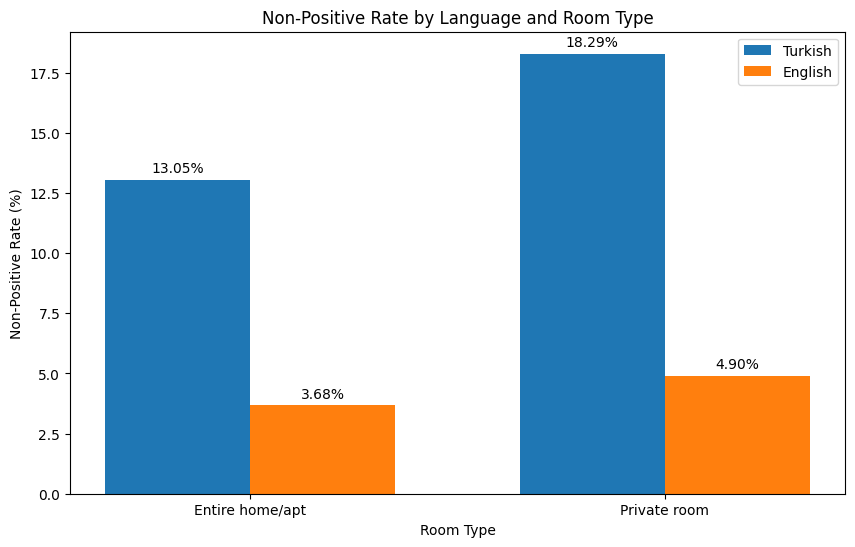

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

room_plot_df = pd.DataFrame({
    "room_type": ["Entire home/apt", "Private room"],
    "Turkish": [13.0540, 18.2857],
    "English": [3.6805, 4.8951]
})

x = np.arange(len(room_plot_df["room_type"]))
width = 0.35

plt.figure(figsize=(10,6))
plt.bar(x - width/2, room_plot_df["Turkish"], width, label="Turkish")
plt.bar(x + width/2, room_plot_df["English"], width, label="English")

plt.xticks(x, room_plot_df["room_type"])
plt.ylabel("Non-Positive Rate (%)")
plt.xlabel("Room Type")
plt.title("Non-Positive Rate by Language and Room Type")
plt.legend()

for i, v in enumerate(room_plot_df["Turkish"]):
    plt.text(i - width/2, v + 0.3, f"{v:.2f}%", ha="center")

for i, v in enumerate(room_plot_df["English"]):
    plt.text(i + width/2, v + 0.3, f"{v:.2f}%", ha="center")

plt.show()

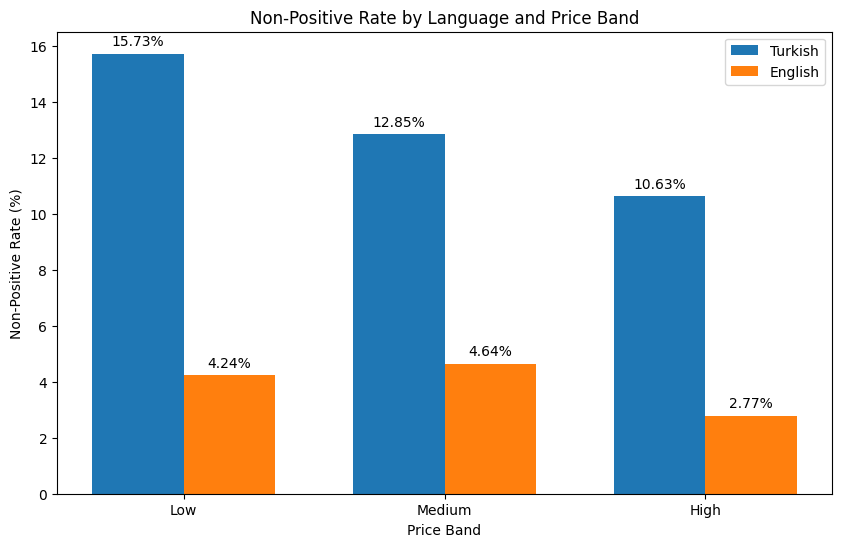

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

price_plot_df = pd.DataFrame({
    "price_band": ["Low", "Medium", "High"],
    "Turkish": [15.7336, 12.8518, 10.6322],
    "English": [4.2353, 4.6398, 2.7731]
})

x = np.arange(len(price_plot_df["price_band"]))
width = 0.35

plt.figure(figsize=(10,6))
plt.bar(x - width/2, price_plot_df["Turkish"], width, label="Turkish")
plt.bar(x + width/2, price_plot_df["English"], width, label="English")

plt.xticks(x, price_plot_df["price_band"])
plt.ylabel("Non-Positive Rate (%)")
plt.xlabel("Price Band")
plt.title("Non-Positive Rate by Language and Price Band")
plt.legend()

for i, v in enumerate(price_plot_df["Turkish"]):
    plt.text(i - width/2, v + 0.3, f"{v:.2f}%", ha="center")

for i, v in enumerate(price_plot_df["English"]):
    plt.text(i + width/2, v + 0.3, f"{v:.2f}%", ha="center")

plt.show()

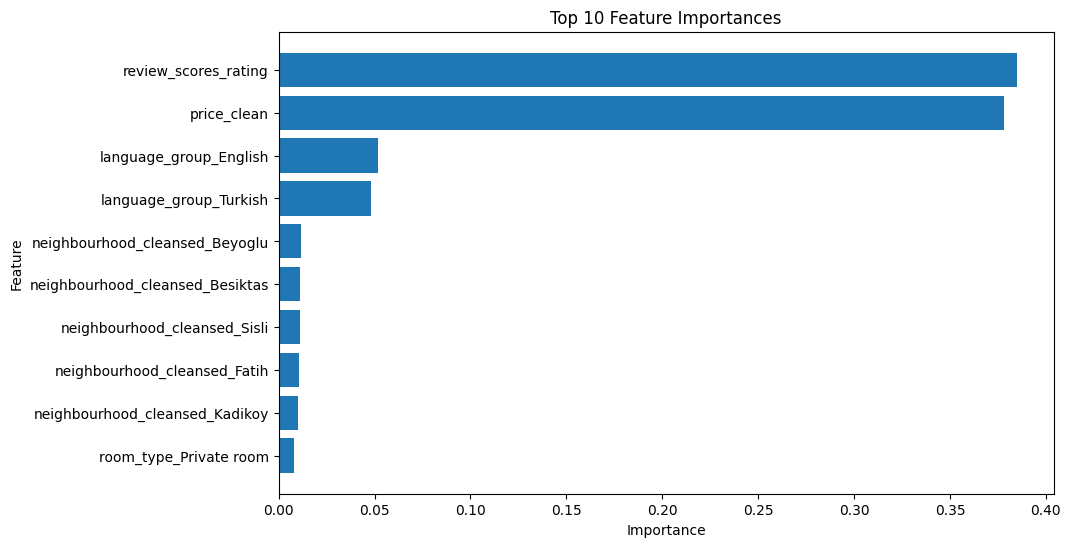

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

fi_top10 = pd.DataFrame({
    "feature": [
        "review_scores_rating",
        "price_clean",
        "language_group_English",
        "language_group_Turkish",
        "neighbourhood_cleansed_Beyoglu",
        "neighbourhood_cleansed_Besiktas",
        "neighbourhood_cleansed_Sisli",
        "neighbourhood_cleansed_Fatih",
        "neighbourhood_cleansed_Kadikoy",
        "room_type_Private room"
    ],
    "importance": [
        0.384823,
        0.378317,
        0.052040,
        0.048336,
        0.011619,
        0.011335,
        0.011294,
        0.010763,
        0.009867,
        0.008189
    ]
})

fi_top10 = fi_top10.sort_values("importance", ascending=True)

plt.figure(figsize=(10,6))
plt.barh(fi_top10["feature"], fi_top10["importance"])
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

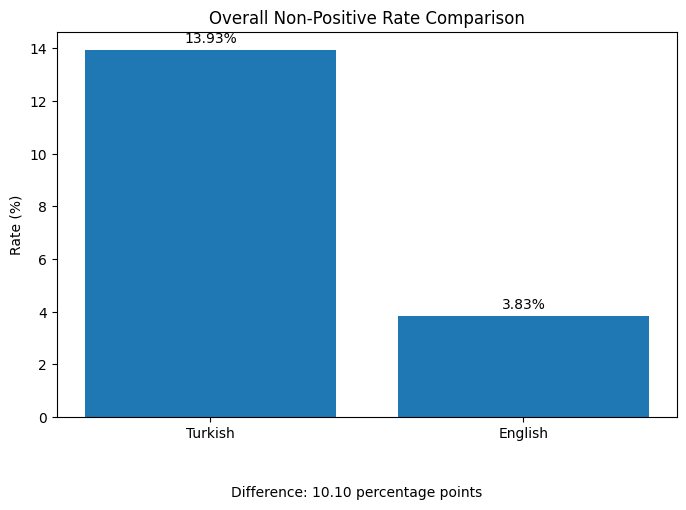

In [ ]:
import matplotlib.pyplot as plt

labels = ["Turkish", "English"]
values = [13.93, 3.83]

plt.figure(figsize=(8,5))
plt.bar(labels, values)
plt.title("Overall Non-Positive Rate Comparison")
plt.ylabel("Rate (%)")

for i, v in enumerate(values):
    plt.text(i, v + 0.3, f"{v:.2f}%", ha="center")

plt.figtext(0.5, -0.05, "Difference: 10.10 percentage points", ha="center", fontsize=10)
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

df_en = pd.read_csv("airbnb_en_analysis_3000_sentiment.csv")
df_tr = pd.read_excel("airbnb_tr_analysis_3000_preprocessed.xlsx")

df_en = df_en[df_en["clean_text"].notna() & (df_en["clean_text"].str.strip() != "")].copy()
df_tr = df_tr[df_tr["clean_text"].notna() & (df_tr["clean_text"].str.strip() != "")].copy()

n_topics_en = 5
n_topics_tr = 4
n_top_words = 12

extra_stopwords_en = [
    "great", "nice", "good", "clean", "amazing", "recommend",
    "would", "really", "well", "everything", "helpful",
    "istanbul", "stay", "place", "host", "also"
]

extra_stopwords_tr = [
    "bir", "olarak", "oldu", "oldukça", "vardı", "var", "çok", "cok",
    "gayet", "sadece", "tekrar", "bey", "beye", "hanım",
    "teşekkür", "teşekkürler", "ederim", "ederiz",
    "kaldım", "kaldık", "gibiydi", "herşey", "hersey",
    "yardımcı", "ilgili", "için", "biraz", "daha",
    "iyi", "güzel", "harika", "mükemmel", "memnun", "tavsiye",
    "temiz", "sahibi", "evin", "oda", "konum", "olabilir", "olsa"
]

def get_topics(lda_model, feature_names, n_top_words=10):
    topics = {}
    for topic_idx, topic in enumerate(lda_model.components_):
        top_features_ind = topic.argsort()[:-n_top_words - 1:-1]
        top_words = [feature_names[i] for i in top_features_ind]
        topics[f"Topic_{topic_idx+1}"] = top_words
    return topics

def assign_dominant_topics(df, topic_matrix, n_topics):
    df = df.copy()
    df["dominant_topic"] = topic_matrix.argmax(axis=1) + 1
    for i in range(n_topics):
        df[f"topic_{i+1}_prob"] = topic_matrix[:, i]
    return df

# EN
vectorizer_en = CountVectorizer(max_df=0.90, min_df=10, stop_words=extra_stopwords_en, ngram_range=(1,2))
dtm_en = vectorizer_en.fit_transform(df_en["clean_text"])
lda_en = LatentDirichletAllocation(n_components=n_topics_en, random_state=42, learning_method="batch")
topic_matrix_en = lda_en.fit_transform(dtm_en)
topics_en = get_topics(lda_en, vectorizer_en.get_feature_names_out(), n_top_words)
df_en_topic = assign_dominant_topics(df_en, topic_matrix_en, n_topics_en)

# TR
vectorizer_tr = CountVectorizer(max_df=0.90, min_df=10, stop_words=extra_stopwords_tr, ngram_range=(1,2))
dtm_tr = vectorizer_tr.fit_transform(df_tr["clean_text"])
lda_tr = LatentDirichletAllocation(n_components=n_topics_tr, random_state=42, learning_method="batch")
topic_matrix_tr = lda_tr.fit_transform(dtm_tr)
topics_tr = get_topics(lda_tr, vectorizer_tr.get_feature_names_out(), n_top_words)
df_tr_topic = assign_dominant_topics(df_tr, topic_matrix_tr, n_topics_tr)

print("ENGLISH TOPICS")
for k, v in topics_en.items():
    print(k, ":", ", ".join(v))

print("\nTURKISH TOPICS")
for k, v in topics_tr.items():
    print(k, ":", ", ".join(v))

df_en_topic.to_csv("airbnb_en_analysis_3000_topics.csv", index=False)
df_tr_topic.to_csv("airbnb_tr_analysis_3000_topics.csv", index=False)

ENGLISH TOPICS
Topic_1 : location, home, perfect, like, house, time, felt, feel, beautiful, friendly, view, comfortable
Topic_2 : street, location, galata, night, walk, bit, overall, tower, floor, galata tower, small, even
Topic_3 : time, come, one, back, thank, always, price, much, view, thanks, location, worth
Topic_4 : location, close, walking, restaurants, distance, responsive, walking distance, walk, public, taksim, attractions, easy
Topic_5 : location, highly, comfortable, easy, friendly, responsive, located, close, recommended, restaurants, wonderful, check

TURKISH TOPICS
Topic_1 : son, yakın, konumu, derece, son derece, genel, kolay, konaklamaydı, konusunda, dönüş, temizdi, güler
Topic_2 : güzeldi, sorun, keyifli, rahat, hızlı, verdi, temizdi, gerçekten, yanıt, geçirdik, zaman, cevap
Topic_3 : tercih, konumu, iyiydi, kesinlikle, temizdi, dışında, onun, fotoğraflarda, gönül, harikaydı, onun dışında, hızlı
Topic_4 : fiyat, performans, fiyat performans, yürüme, tek, yakın, giriş,

In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation


df_en = pd.read_csv("airbnb_en_analysis_3000_sentiment.csv")
df_tr = pd.read_excel("tr_3000_with_final_binary_labels.xlsx")

df_en_negneu = df_en[df_en["sentiment_label"].isin(["negative", "neutral"])].copy()
df_tr_negneu = df_tr[df_tr["final_binary_label"].isin(["non_positive"])].copy()

df_en_negneu = df_en_negneu[df_en_negneu["clean_text"].notna() & (df_en_negneu["clean_text"].str.strip() != "")]
df_tr_negneu = df_tr_negneu[df_tr_negneu["clean_text"].notna() & (df_tr_negneu["clean_text"].str.strip() != "")]

extra_stopwords_en = [
    "great", "nice", "good", "clean", "amazing", "recommend",
    "would", "really", "well", "everything", "helpful",
    "istanbul", "stay", "place", "host", "also",
    "location", "close", "walk"
]

extra_stopwords_tr = [
    "bir", "olarak", "oldu", "oldukça", "vardı", "var", "çok", "cok",
    "gayet", "sadece", "tekrar", "bey", "beye", "hanım",
    "teşekkür", "teşekkürler", "ederim", "ederiz",
    "kaldım", "kaldık", "gibiydi", "herşey", "hersey",
    "yardımcı", "ilgili", "için", "biraz", "daha",
    "iyi", "güzel", "harika", "mükemmel", "memnun", "tavsiye",
    "temiz", "sahibi", "evin", "oda", "konum", "konumu",
    "fakat", "ancak", "değil", "değildi", "yok", "yoktu"
]

def get_topics(lda_model, feature_names, n_top_words=12):
    topics = {}
    for topic_idx, topic in enumerate(lda_model.components_):
        top_idx = topic.argsort()[:-n_top_words - 1:-1]
        topics[f"Topic_{topic_idx+1}"] = [feature_names[i] for i in top_idx]
    return topics

# EN
vec_en = CountVectorizer(max_df=0.95, min_df=3, stop_words=extra_stopwords_en, ngram_range=(1,2))
dtm_en = vec_en.fit_transform(df_en_negneu["clean_text"])
lda_en = LatentDirichletAllocation(n_components=3, random_state=42, learning_method="batch")
topics_en = get_topics(lda_en.fit(dtm_en), vec_en.get_feature_names_out())

# TR
vec_tr = CountVectorizer(max_df=0.95, min_df=3, stop_words=extra_stopwords_tr, ngram_range=(1,2))
dtm_tr = vec_tr.fit_transform(df_tr_negneu["clean_text"])
lda_tr = LatentDirichletAllocation(n_components=3, random_state=42, learning_method="batch")
topics_tr = get_topics(lda_tr.fit(dtm_tr), vec_tr.get_feature_names_out())

print("ENGLISH NEG/NEU TOPICS")
for k, v in topics_en.items():
    print(k, ":", ", ".join(v))

print("\nTURKISH NEG/NEU TOPICS")
for k, v in topics_tr.items():
    print(k, ":", ", ".join(v))

ENGLISH NEG/NEU TOPICS
Topic_1 : internet, problem, dirty, night, airbnb, next, issues, one, smell, time, floor, experience
Topic_2 : water, even, noise, house, bad, hot, people, shower, though, one, issues, view
Topic_3 : bathroom, one, night, broken, get, shower, building, old, unit, cleaning, bed, small

TURKISH NEG/NEU TOPICS
Topic_1 : temizlik, genel, güzeldi, olduğu, dışında, temizdi, yatak, mutfak, ses, giriş, gece, kötü
Topic_2 : giriş, dışında, zaman, iyiydi, kadar, gün, onun, sorun, temizlik, herhangi, olduğu, onun dışında
Topic_3 : onun, dışında, sorun, onun dışında, tek, olması, yatak, sıkıntı, fazla, iyiydi, genel, gece


In [ ]:
import pandas as pd
import numpy as np

df_en = pd.read_csv("airbnb_en_analysis_3000_sentiment.csv")
df_tr = pd.read_excel("tr_3000_with_final_binary_labels.xlsx")

def ratio_of_label(series, label):
    return (series == label).mean()

# Prepare sentiment columns for df_tr to match df_en's structure for aggregation
df_tr["sentiment_score_tr"] = df_tr["final_binary_label"].map({"positive": 1, "non_positive": 0})
df_tr["sentiment_label_tr"] = df_tr["final_binary_label"].map({"positive": "positive", "non_positive": "negative"})

agg_en = df_en.groupby("listing_id").agg(
    review_count_en=("listing_id", "size"),
    mean_sentiment_en=("sentiment_score", "mean"),
    median_sentiment_en=("sentiment_score", "median"),
    positive_ratio_en=("sentiment_label", lambda x: ratio_of_label(x, "positive")),
    negative_ratio_en=("sentiment_label", lambda x: ratio_of_label(x, "negative")),
    neutral_ratio_en=("sentiment_label", lambda x: ratio_of_label(x, "neutral"))
).reset_index()

agg_tr = df_tr.groupby("listing_id").agg(
    review_count_tr=("listing_id", "size"),
    mean_sentiment_tr=("sentiment_score_tr", "mean"),
    median_sentiment_tr=("sentiment_score_tr", "median"),
    positive_ratio_tr=("sentiment_label_tr", lambda x: ratio_of_label(x, "positive")),
    negative_ratio_tr=("sentiment_label_tr", lambda x: ratio_of_label(x, "negative"))
    # neutral_ratio_tr is not applicable for binary labels, so it's removed
).reset_index()

listing_sentiment = pd.merge(agg_en, agg_tr, on="listing_id", how="outer")

# genel skor
for col in [
    "review_count_en","mean_sentiment_en","median_sentiment_en",
    "positive_ratio_en","negative_ratio_en","neutral_ratio_en",
    "review_count_tr","mean_sentiment_tr","median_sentiment_tr",
    "positive_ratio_tr","negative_ratio_tr"
]:
    if col in listing_sentiment.columns:
        listing_sentiment[col] = listing_sentiment[col].fillna(0)

listing_sentiment["review_count_all"] = listing_sentiment["review_count_en"] + listing_sentiment["review_count_tr"]

listing_sentiment["mean_sentiment_all"] = np.where(
    listing_sentiment["review_count_all"] > 0,
    (
        listing_sentiment["mean_sentiment_en"] * listing_sentiment["review_count_en"] +
        listing_sentiment["mean_sentiment_tr"] * listing_sentiment["review_count_tr"]
    ) / listing_sentiment["review_count_all"],
    np.nan
)

listing_sentiment.to_csv("listing_level_sentiment_features.csv", index=False)
listing_sentiment.head()

,listing_id,review_count_en,mean_sentiment_en,median_sentiment_en,positive_ratio_en,negative_ratio_en,neutral_ratio_en,review_count_tr,mean_sentiment_tr,median_sentiment_tr,positive_ratio_tr,negative_ratio_tr,review_count_all,mean_sentiment_all
0,362196,1.0,0.707900,0.7079,1.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.7079
1,371112,1.0,0.992200,0.9922,1.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.9922
2,406324,1.0,0.933600,0.9336,1.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.9336
3,519468,0.0,0.000000,0.0000,0.000000,0.000000,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0000
4,520238,3.0,0.607867,0.8402,0.666667,0.333333,0.0,1.0,1.0,1.0,1.0,0.0,4.0,0.7059


In [ ]:
df_en = pd.read_csv("airbnb_en_analysis_3000_sentiment.csv")
df_tr = pd.read_excel("tr_3000_with_final_binary_labels.xlsx")

# dominant topic oranları
topic_share_en = pd.crosstab(df_en_topic["listing_id"], df_en_topic["dominant_topic"], normalize="index")
topic_share_en.columns = [f"en_topic_{c}_share" for c in topic_share_en.columns]
topic_share_en = topic_share_en.reset_index()

topic_share_tr = pd.crosstab(df_tr_topic["listing_id"], df_tr_topic["dominant_topic"], normalize="index")
topic_share_tr.columns = [f"tr_topic_{c}_share" for c in topic_share_tr.columns]
topic_share_tr = topic_share_tr.reset_index()

listing_topics = pd.merge(topic_share_en, topic_share_tr, on="listing_id", how="outer").fillna(0)
listing_topics.to_csv("listing_level_topic_features.csv", index=False)
listing_topics.head()

,listing_id,en_topic_1_share,en_topic_2_share,en_topic_3_share,en_topic_4_share,en_topic_5_share,tr_topic_1_share,tr_topic_2_share,tr_topic_3_share,tr_topic_4_share
0,362196,0.000000,1.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
1,371112,0.000000,1.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0
2,406324,0.000000,0.000000,1.000000,0.0,0.0,0.0,0.0,0.0,0.0
3,519468,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,1.0,0.0
4,520238,0.333333,0.333333,0.333333,0.0,0.0,1.0,0.0,0.0,0.0


In [ ]:
listings_clean = pd.read_csv("listings_clean.csv")
listing_sentiment = pd.read_csv("listing_level_sentiment_features.csv")
listing_topics = pd.read_csv("listing_level_topic_features.csv")

price_model_df = listings_clean.merge(listing_sentiment, left_on="id", right_on="listing_id", how="left")
price_model_df = price_model_df.merge(listing_topics, left_on="id", right_on="listing_id", how="left")

price_model_df.to_csv("price_model_base_2025.csv", index=False)
price_model_df.head()

,id,source,name,description,neighborhood_overview,host_id,host_since,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_neighbourhood,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,listing_id_x,review_count_en,mean_sentiment_en,median_sentiment_en,positive_ratio_en,negative_ratio_en,neutral_ratio_en,review_count_tr,mean_sentiment_tr,median_sentiment_tr,positive_ratio_tr,negative_ratio_tr,review_count_all,mean_sentiment_all,listing_id_y,en_topic_1_share,en_topic_2_share,en_topic_3_share,en_topic_4_share,en_topic_5_share,tr_topic_1_share,tr_topic_2_share,tr_topic_3_share,tr_topic_4_share
0,1342043490398914341,city scrape,Отдельная квартира на Фатих(Балат).,A cozy apartment in the historical area of Bal...,The apartment is in one of the most atmospheri...,444141348,2022-02-08,within an hour,100.0,82.0,t,NaN,7.0,"['email', 'phone']",t,t,"Fatih, İstanbul, Turkey",Fatih,NaN,41.031098,28.945879,Entire rental unit,Entire home/apt,4,0.5,Half-bath,1.0,2.0,"[""Kitchen"", ""Room-darkening shades"", ""Oven"", ""...",2290.0,5,365,5.0,5.0,365.0,365.0,5.0,365.0,NaN,t,30,60,90,180,2025-09-30,4,4,1,93,0,40,91600.0,2025-03-07,2025-09-19,4.50,4.50,5.00,5.00,5.0,4.50,4.50,A28394518,f,2,2,0,0,0.58,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1342082318675744621,city scrape,Blue standart 7,Blue apartments located at perfect point that ...,NaN,304448264,2019-10-25,within an hour,96.0,99.0,f,NaN,9.0,"['email', 'phone']",t,t,NaN,Beyoglu,NaN,41.038460,28.983504,Private room in bed and breakfast,Private room,2,1.0,1 private bath,1.0,1.0,"[""Kitchen"", ""Room-darkening shades"", ""Heating ...",1101.0,7,360,6.0,7.0,1125.0,1125.0,7.0,1125.0,NaN,t,13,23,53,328,2025-10-01,4,4,1,55,0,56,61656.0,2025-04-07,2025-09-02,3.75,4.25,4.00,4.50,4.5,5.00,4.25,12-9738,t,7,6,1,0,0.67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1342210705450176162,city scrape,Central Located Stylish Flat,"Located just 20 meters from Istiklal Street, o...",NaN,380165223,2020-12-14,within an hour,97.0,100.0,t,NaN,19.0,"['email', 'phone']",t,t,NaN,Beyoglu,NaN,41.034284,28.981304,Entire rental unit,Entire home/apt,3,1.0,1 bath,1.0,1.0,"[""Kitchen"", ""Room-darkening shades"", ""Fire ext...",3430.0,2,365,1.0,2.0,1125.0,1125.0,1.9,1125.0,NaN,t,18,48,75,327,2025-10-01,26,26,0,75,0,156,535080.0,2025-02-17,2025-08-19,4.96,4.85,4.77,4.92,5.0,4.85,4.81,2022-34-2652,t,13,13,0,0,3.44,1.342211e+18,1.0,0.8316,0.8316,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.8316,1.342211e+18,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1342423666721201645,city scrape,Grand Aura Nişantaşı (3+1 buyuk daire),We offer a unique 3 bedroom accommodation expe...,NaN,211277594,2018-08-23,within an hour,100.0,95.0,t,Nişantaşı,6.0,['phone'],t,t,NaN,Sisli,NaN,41.054742,28.989057,Entire place,Entire home/apt,6,1.0,1 bath,1.0,3.0,"[""Crib"", ""Kitchen"", ""Refrigerator"", ""Lo

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


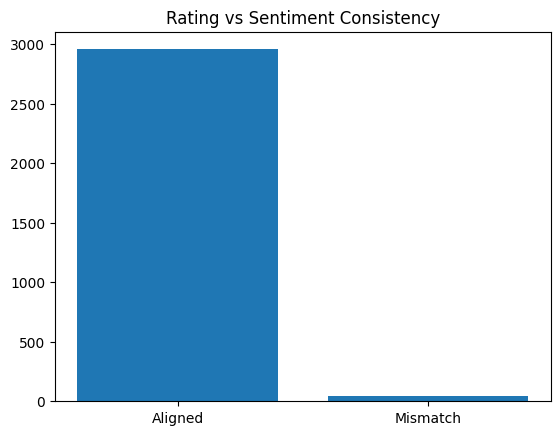

In [ ]:
import pandas as pd
from nltk.sentiment import SentimentIntensityAnalyzer
import nltk

nltk.download('vader_lexicon')

sia = SentimentIntensityAnalyzer()

# -----------------------------
# 1. English only (since sentiment score exists)
# -----------------------------
df_en = df[df['language'] == 'en'].copy()

# -----------------------------
# 2. Sentiment score
# -----------------------------
df_en['sentiment'] = df_en['clean_text'].astype(str).apply(
    lambda x: sia.polarity_scores(x)['compound']
)

# -----------------------------
# 3. Normalize rating (assume 1–5 scale)
# -----------------------------
df_en['rating_norm'] = (df_en['review_scores_value'] - 3) / 2  # maps to approx [-1, +1]

# -----------------------------
# 4. Define mismatch rules
# -----------------------------

# Negative sentiment but high rating
df_en['positive_rating_negative_text'] = (
    (df_en['review_scores_value'] >= 4) & (df_en['sentiment'] < -0.2)
)

# Low rating but positive sentiment
df_en['negative_rating_positive_text'] = (
    (df_en['review_scores_value'] <= 2) & (df_en['sentiment'] > 0.2)
)

# -----------------------------
# 5. Extract mismatches
# -----------------------------
mismatch_df = df_en[
    df_en['positive_rating_negative_text'] |
    df_en['negative_rating_positive_text']
].copy()

# -----------------------------
# 6. Summary statistics
# -----------------------------
summary = {
    "total_reviews": len(df_en),
    "mismatch_count": len(mismatch_df),
    "mismatch_ratio": len(mismatch_df) / len(df_en)
}

summary

import matplotlib.pyplot as plt

labels = ['Aligned', 'Mismatch']
values = [
    len(df_en) - len(mismatch_df),
    len(mismatch_df)
]

plt.bar(labels, values)
plt.title("Rating vs Sentiment Consistency")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from nltk.sentiment import SentimentIntensityAnalyzer
import nltk

nltk.download('vader_lexicon')

sia = SentimentIntensityAnalyzer()

# Only English reviews
df_en = df[df['language'] == 'en'].copy()

# Sentiment score
df_en['sentiment'] = df_en['clean_text'].astype(str).apply(
    lambda x: sia.polarity_scores(x)['compound']
)

# Rating column (Airbnb: review_scores_value assumed 1-5)
df_en['rating'] = df_en['review_scores_value']

# Mismatch conditions
df_en['high_rating_negative_text'] = (
    (df_en['rating'] >= 4) & (df_en['sentiment'] < -0.2)
)

df_en['low_rating_positive_text'] = (
    (df_en['rating'] <= 2) & (df_en['sentiment'] > 0.2)
)

df_en['mismatch'] = (
    df_en['high_rating_negative_text'] |
    df_en['low_rating_positive_text']
)

# Summary
mismatch_count = df_en['mismatch'].sum()
total_reviews = len(df_en)
mismatch_ratio = mismatch_count / total_reviews

print("Mismatch Count:", mismatch_count)
print("Mismatch Ratio:", mismatch_ratio)

# Breakdown
print("\nMismatch Types:")
print(df_en['mismatch'].value_counts())

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Mismatch Count: 43
Mismatch Ratio: 0.014333333333333333

Mismatch Types:
mismatch
False    2957
True       43
Name: count, dtype: int64


In [ ]:
import pandas as pd
from nltk.sentiment import SentimentIntensityAnalyzer
import nltk

nltk.download('vader_lexicon')

sia = SentimentIntensityAnalyzer()

# English reviews only
df_en = df[df['language'] == 'en'].copy()

# Sentiment score
df_en['sentiment'] = df_en['clean_text'].astype(str).apply(
    lambda x: sia.polarity_scores(x)['compound']
)

# Rating
df_en['rating'] = df_en['review_scores_value']

# Mismatch rules
df_en['high_rating_negative_text'] = (
    (df_en['rating'] >= 4) & (df_en['sentiment'] < -0.2)
)

df_en['low_rating_positive_text'] = (
    (df_en['rating'] <= 2) & (df_en['sentiment'] > 0.2)
)

df_en['mismatch'] = (
    df_en['high_rating_negative_text'] |
    df_en['low_rating_positive_text']
)

# -----------------------------
# SHOW MISMATCH CASES
# -----------------------------
mismatch_df = df_en[df_en['mismatch']].copy()

# Sort for easier inspection
mismatch_df = mismatch_df.sort_values(by='sentiment')

# Display key columns
mismatch_df[[
    'listing_id',
    'clean_text',
    'rating',
    'sentiment'
]].head(30)

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


,listing_id,clean_text,rating,sentiment
5104,598531238705589632,second booking within weeks via airbnb disappo...,4.25,-0.9705
4266,983708539863575552,property unfortunately disappointing located u...,4.62,-0.9445
5836,846266802719815680,arrived building smelled like cat piss rubbish...,4.63,-0.9423
5911,1025894249118696960,much smaller appears photos specifically leavi...,4.70,-0.9360
4277,1370389562487825920,house photos two bedrooms single beds double s...,4.21,-0.8979
5444,1225262963018027008,disappointing private separate entrance meanin...,4.79,-0.8567
3830,751842052760832640,nasty shower cockroaches working lights frustr...,4.33,-0.8553
4469,896393536889369088,regret drop stars mainly internet property thr...,4.33,-0.8271
4210,45603108,good location advice really invest new furnitu...,4.75,-0.8204
4334,1218222514925363968,hello unsatisfactory bed mattress hollow middl...,4.50,-0.7980


In [ ]:
import pandas as pd
import numpy as np
from nltk.sentiment import SentimentIntensityAnalyzer
import nltk

nltk.download('vader_lexicon')

sia = SentimentIntensityAnalyzer()

# -----------------------------
# 1. Split datasets
# -----------------------------
df_en = df[df['language'] == 'en'].copy()
df_tr = df[df['language'] == 'tr'].copy()

# -----------------------------
# 2. Sentiment EN (VADER)
# -----------------------------
df_en['sentiment'] = df_en['clean_text'].astype(str).apply(
    lambda x: sia.polarity_scores(x)['compound']
)

# -----------------------------
# 3. Sentiment TR (ML model assumed)
# -----------------------------
df_tr['sentiment'] = df_tr['clean_text'].astype(str).apply(
    lambda x: model.predict_proba([x])[0][1]  # positive probability
)

# -----------------------------
# 4. Ratings
# -----------------------------
df_en['rating'] = df_en['review_scores_value']
df_tr['rating'] = df_tr['review_scores_value']

# -----------------------------
# 5. Mismatch rules (EN)
# -----------------------------
df_en['mismatch'] = (
    ((df_en['rating'] >= 4) & (df_en['sentiment'] < -0.2)) |
    ((df_en['rating'] <= 2) & (df_en['sentiment'] > 0.2))
)

# -----------------------------
# 6. Mismatch rules (TR)
# -----------------------------
df_tr['mismatch'] = (
    ((df_tr['rating'] >= 4) & (df_tr['sentiment'] < 0.5)) |
    ((df_tr['rating'] <= 2) & (df_tr['sentiment'] > 0.5))
)

# -----------------------------
# 7. SUMMARY FUNCTION
# -----------------------------
def summarize(df, name):
    return {
        "language": name,
        "total": len(df),
        "mismatch_count": df['mismatch'].sum(),
        "mismatch_ratio": df['mismatch'].mean()
    }

summary = pd.DataFrame([
    summarize(df_en, "English"),
    summarize(df_tr, "Turkish")
])

summary

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


,language,total,mismatch_count,mismatch_ratio
0,English,3000,43,0.014333
1,Turkish,3000,77,0.025667


In [ ]:
from statsmodels.stats.proportion import proportions_ztest
import numpy as np

# counts
count = np.array([77, 43])      # mismatch counts (TR, EN)
nobs = np.array([3000, 3000])   # total reviews

stat, p_value = proportions_ztest(count, nobs)

print("Z-statistic:", stat)
print("p-value:", p_value)

Z-statistic: 3.1352722326440996
p-value: 0.00171694698821905


In [ ]:
import statsmodels.api as sm

df_model = df_en.copy()

# The 'is_turkish' feature is not relevant for df_en (English only data)
# and causes multicollinearity with the intercept as it will always be 0.
# Removing it from X.
# df_model['is_turkish'] = (df_model['language'] == 'tr').astype(int)

X = df_model[['rating', 'sentiment']]
y = df_model['mismatch'].astype(int)

X = sm.add_constant(X)

model = sm.Logit(y, X).fit()

print(model.summary())

Optimization terminated successfully.
         Current function value: 0.015326
         Iterations 11
                           Logit Regression Results                           
Dep. Variable:               mismatch   No. Observations:                 3000
Model:                          Logit   Df Residuals:                     2997
Method:                           MLE   Df Model:                            2
Date:                Mon, 01 Jun 2026   Pseudo R-squ.:                  0.7959
Time:                        10:12:14   Log-Likelihood:                -45.978
converged:                       True   LL-Null:                       -225.23
Covariance Type:            nonrobust   LLR p-value:                 1.416e-78
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -4.4711      1.823     -2.453      0.014      -8.044      -0.898
rating         0.4534      0

In [ ]:
import numpy as np
import pandas as pd

# Odds Ratio hesaplama
params = model.params
odds_ratios = np.exp(params)

results = pd.DataFrame({
    "Katsayı (coef)": params,
    "Odds Ratio": odds_ratios,
    "p-değeri": model.pvalues
})

results

,Katsayı (coef),Odds Ratio,p-değeri
const,-4.471063,0.011435,1.417998e-02
rating,0.453367,1.573601,2.511732e-01
sentiment,-7.281735,0.000688,1.389280e-19
